# 01 - Exploratory Data Analysis

Data source: reporting views in the `rpt` schema of **OlistDB** (SQL Server).
All business rules (delivered orders only, revenue excluding freight, customer = `customer_unique_id`) live in the SQL views, so Python and Power BI report the same numbers.


## 1. Connection test


In [109]:
import pandas as pd
from db_utils import run_query

# Who am I connected as, and to which database?
run_query("""
    SELECT DB_NAME()      AS db,
           SUSER_NAME()   AS login_user,
           @@SERVERNAME   AS server_name,
           CAST(SERVERPROPERTY('ProductVersion') AS varchar(20)) AS sql_version
""")

,db,login_user,server_name,sql_version
0,OlistDB,MSI\ms,MSI\SQLEXPRESS,17.0.1000.7


## 2. Load the reporting views

In [110]:
# List every column in the rpt views (name + SQL data type)
cols = run_query("""
    SELECT TABLE_NAME AS view_name, COLUMN_NAME AS column_name, DATA_TYPE AS data_type
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'rpt'
    ORDER BY TABLE_NAME, ORDINAL_POSITION
""")
print(cols.to_string(index=False))

         view_name        column_name data_type
 vw_CohortActivity       customer_key       int
 vw_CohortActivity       cohort_month  nvarchar
 vw_CohortActivity     activity_month  nvarchar
 vw_CohortActivity       month_number       int
 vw_CustomerOrders           order_id   varchar
 vw_CustomerOrders       customer_key       int
 vw_CustomerOrders customer_unique_id   varchar
 vw_CustomerOrders     customer_state   varchar
 vw_CustomerOrders        purchase_ts datetime2
 vw_CustomerOrders      purchase_date      date
 vw_CustomerOrders     purchase_month      char
 vw_CustomerOrders          order_seq    bigint
 vw_CustomerOrders         item_count       int
 vw_CustomerOrders            revenue   decimal
 vw_CustomerOrders      freight_value   decimal
 vw_CustomerOrders      payment_value   decimal
 vw_CustomerOrders      delivery_days       int
 vw_CustomerOrders         delay_days       int
 vw_CustomerOrders            is_late       bit
 vw_CustomerOrders       review_score   

In [111]:
from db_utils import read_view

views = ["vw_CustomerOrders", "vw_CustomerSummary", "vw_CohortActivity", "vw_MonthlyKPIs"]
data = {v: read_view(v) for v in views}   # dict: view name -> DataFrame

for name, df in data.items():
    print(f"{name:<20} rows={len(df):>8,}  cols={df.shape[1]}")

vw_CustomerOrders    rows=  96,470  cols=16
vw_CustomerSummary   rows=  93,350  cols=12
vw_CohortActivity    rows=  95,186  cols=4
vw_MonthlyKPIs       rows=      23  cols=8


In [112]:
# Python must reproduce the same totals we validated in SQL (Phase 1)
checks = {
    "Delivered orders": (len(data["vw_CustomerOrders"]), 96_470),
    "Unique customers": (len(data["vw_CustomerSummary"]), 93_350),
}
for label, (actual, expected) in checks.items():
    status = "OK" if actual == expected else "MISMATCH"
    print(f"{status:<9} {label}: {actual:,} (expected {expected:,})")

OK        Delivered orders: 96,470 (expected 96,470)
OK        Unique customers: 93,350 (expected 93,350)


In [113]:
# Revenue must match Phase 1 in every view (revenue excludes freight)
EXPECTED_REVENUE = 13_220_248.93
totals = {
    "vw_CustomerOrders":  data["vw_CustomerOrders"]["revenue"].sum(),
    "vw_CustomerSummary": data["vw_CustomerSummary"]["revenue"].sum(),
    "vw_MonthlyKPIs":     data["vw_MonthlyKPIs"]["revenue"].sum(),
}
for name, total in totals.items():
    status = "OK" if round(total, 2) == EXPECTED_REVENUE else "MISMATCH"
    print(f"{status:<9} {name:<20} {total:,.2f}")

# Money columns should arrive as numbers (float64), not object
print()
print(data["vw_CustomerOrders"][["revenue", "freight_value", "payment_value", "purchase_ts", "purchase_date"]].dtypes)

OK        vw_CustomerOrders    13,220,248.93
OK        vw_CustomerSummary   13,220,248.93
OK        vw_MonthlyKPIs       13,220,248.93

revenue                 float64
freight_value           float64
payment_value           float64
purchase_ts      datetime64[us]
purchase_date            object
dtype: object


## 3. Prepare data for EDA

- Convert date/month columns to real datetime types.
- Analysis window: **Jan 2017 - Aug 2018**. 2016 has almost no orders, so growth rates there are meaningless.


In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

# One consistent chart style for the whole notebook
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.titleweight"] = "bold"

# Short names + copies, so the original data stays untouched
orders    = data["vw_CustomerOrders"].copy()
customers = data["vw_CustomerSummary"].copy()
cohort    = data["vw_CohortActivity"].copy()
monthly   = data["vw_MonthlyKPIs"].copy()

# Text / object columns -> real datetimes (format is strict: fails loudly if the data is not YYYY-MM)
orders["purchase_date"]   = pd.to_datetime(orders["purchase_date"])
orders["purchase_month"]  = pd.to_datetime(orders["purchase_month"], format="%Y-%m")
monthly["purchase_month"] = pd.to_datetime(monthly["purchase_month"], format="%Y-%m")
cohort["cohort_month"]    = pd.to_datetime(cohort["cohort_month"], format="%Y-%m")
cohort["activity_month"]  = pd.to_datetime(cohort["activity_month"], format="%Y-%m")
monthly = monthly.sort_values("purchase_month").reset_index(drop=True)

# Analysis window for time-based charts
START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-08-01")
monthly_win = monthly[monthly["purchase_month"].between(START, END)]

print("Order dates :", orders["purchase_date"].min().date(), "->", orders["purchase_date"].max().date())
print("Months total:", len(monthly), "| in window:", len(monthly_win))
print("Orders outside window:", (~orders["purchase_month"].between(START, END)).sum())
print()
print(orders[["purchase_date", "purchase_month"]].dtypes)

Order dates : 2016-09-15 -> 2018-08-29
Months total: 23 | in window: 20
Orders outside window: 267

purchase_date      datetime64[s]
purchase_month    datetime64[us]
dtype: object


## 4. Is the business growing?

**Question:** How did monthly revenue and order volume change between Jan 2017 and Aug 2018?


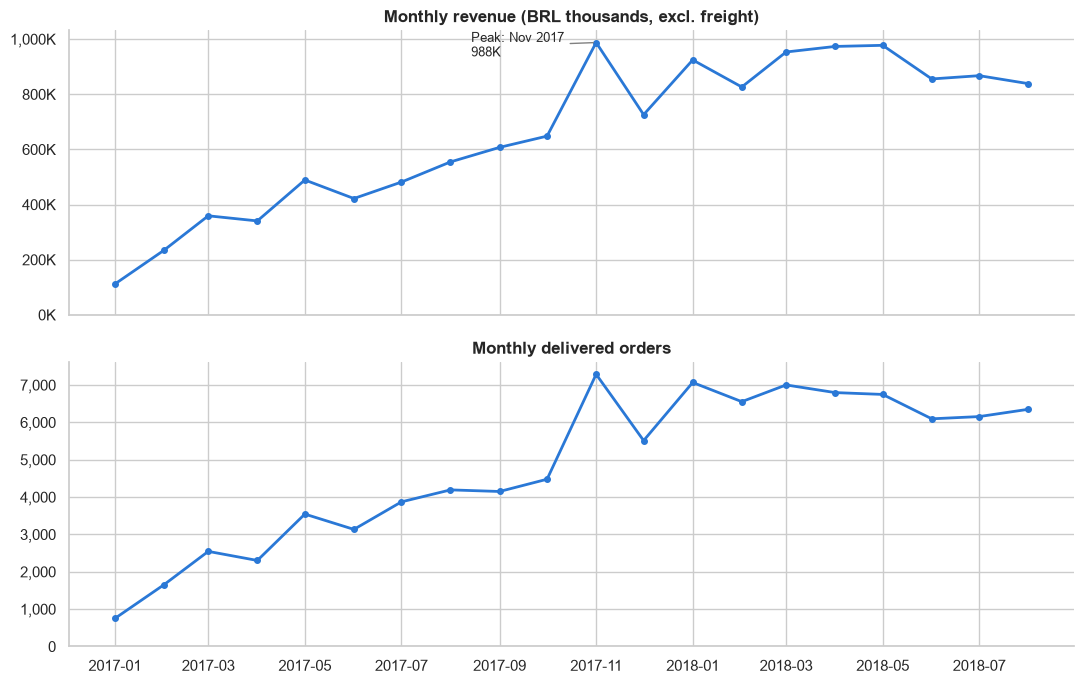

In [115]:
from pathlib import Path
import matplotlib.ticker as mtick

BLUE = "#2a78d6"                 # one hue: each panel shows a single series
IMG_DIR = Path("../images")       # charts saved here for the README
IMG_DIR.mkdir(exist_ok=True)

# Two panels sharing the time axis (never one chart with two y-axes)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(monthly_win["purchase_month"], monthly_win["revenue"] / 1_000, color=BLUE, lw=2, marker="o", ms=4)
ax1.set_title("Monthly revenue (BRL thousands, excl. freight)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}K"))
ax1.set_ylim(bottom=0)

ax2.plot(monthly_win["purchase_month"], monthly_win["orders"], color=BLUE, lw=2, marker="o", ms=4)
ax2.set_title("Monthly delivered orders")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2.set_ylim(bottom=0)

# Label only the peak month (selective direct label)
peak = monthly_win.loc[monthly_win["revenue"].idxmax()]
ax1.annotate(f"Peak: {peak['purchase_month']:%b %Y}\n{peak['revenue']/1_000:,.0f}K",
             xy=(peak["purchase_month"], peak["revenue"] / 1_000),
             xytext=(-90, -10), textcoords="offset points",
             arrowprops=dict(arrowstyle="-", color="gray"), fontsize=9)

for ax in (ax1, ax2):
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(IMG_DIR / "01_monthly_revenue_orders.png", dpi=150, bbox_inches="tight")
plt.show()

In [116]:
# Numbers behind the chart: compare the SAME months (Jan-Aug) of both years
def period(y):
    m = monthly_win[(monthly_win["purchase_month"].dt.year == y) & (monthly_win["purchase_month"].dt.month <= 8)]
    return pd.Series({"revenue": m["revenue"].sum(), "orders": m["orders"].sum(),
                      "avg_monthly_revenue": m["revenue"].mean()})

yoy = pd.DataFrame({"Jan-Aug 2017": period(2017), "Jan-Aug 2018": period(2018)})
yoy["change_%"] = (yoy["Jan-Aug 2018"] / yoy["Jan-Aug 2017"] - 1) * 100
print(yoy.round(1).to_string())

# Within 2018: is there still growth month to month?
m18 = monthly_win[monthly_win["purchase_month"].dt.year == 2018][["purchase_month", "revenue", "orders", "avg_order_value"]]
print()
print(m18.assign(purchase_month=m18["purchase_month"].dt.strftime("%Y-%m")).to_string(index=False))

                     Jan-Aug 2017  Jan-Aug 2018  change_%
revenue                 2993277.1     7217172.2     141.1
orders                    21997.0       52777.0     139.9
avg_monthly_revenue      374159.6      902146.5     141.1

purchase_month   revenue  orders  avg_order_value
       2018-01 924645.00    7069           130.80
       2018-02 826437.13    6555           126.08
       2018-03 953356.25    7003           136.14
       2018-04 973534.09    6798           143.21
       2018-05 977544.69    6749           144.84
       2018-06 855591.97    6096           140.35
       2018-07 867486.47    6156           140.92
       2018-08 838576.64    6351           132.04


**Insight - growth came from more orders, and it stopped in 2018**

- Jan-Aug 2018 vs Jan-Aug 2017: revenue **+141%** and orders **+140%**. Average order value stayed flat (~136 BRL in both periods), so all the growth came from **more orders, not bigger baskets**.
- Within 2018 there is **no further growth**: revenue moved between ~830K and ~980K per month. Jun-Aug (~840-870K) is even lower than Mar-May (~950-980K).
- Nov 2017 (Black Friday) is the single peak month (988K), followed by a drop in Dec.
- Caveat: only one full year of history, so we cannot separate a real slowdown from normal seasonality.

**Business meaning:** with only 3% repeat customers (Phase 1), revenue depends almost entirely on acquiring new customers every month. Once acquisition plateaued, revenue plateaued. Retention is the main growth lever.


## 5. How often do customers buy?

**Questions:** How many customers come back for a second order? How much revenue do repeat customers bring? And when they do come back, how long does it take?


In [117]:
# --- 1) Customers by number of orders (group 4+ together) ---
freq = customers["orders"].clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4+"})
freq_tbl = (customers.assign(order_group=freq)
            .groupby("order_group")
            .agg(customers=("customer_key", "count"), revenue=("revenue", "sum")))
freq_tbl["customers_%"] = freq_tbl["customers"] / freq_tbl["customers"].sum() * 100
freq_tbl["revenue_%"]   = freq_tbl["revenue"]   / freq_tbl["revenue"].sum()   * 100
print(freq_tbl.round(1).to_string())

repeat = customers["is_repeat_customer"] == 1
print(f"\nRepeat customers: {repeat.sum():,} ({repeat.mean():.1%}) "
      f"-> {customers.loc[repeat, 'revenue'].sum() / customers['revenue'].sum():.1%} of revenue")

# --- 2) Days between 1st and 2nd order (only customers who came back) ---
first_two = (orders[orders["order_seq"] <= 2]
             .pivot(index="customer_key", columns="order_seq", values="purchase_ts")
             .dropna())
gap_days = (first_two[2] - first_two[1]).dt.days
print(f"\nCustomers with a 2nd order: {len(gap_days):,}")
print(f"Same day (gap = 0): {(gap_days == 0).mean():.1%}")
print(gap_days.describe(percentiles=[.25, .5, .75, .9]).round(0).to_string())

             customers     revenue  customers_%  revenue_%
order_group                                               
1                90549  12491840.2         97.0       94.5
2                 2573    631274.9          2.8        4.8
3                  181     65974.4          0.2        0.5
4+                  47     31159.4          0.1        0.2

Repeat customers: 2,801 (3.0%) -> 5.5% of revenue

Customers with a 2nd order: 2,801
Same day (gap = 0): 30.5%
count    2801.0
mean       81.0
std       110.0
min         0.0
25%         0.0
50%        28.0
75%       126.0
90%       246.0
max       608.0


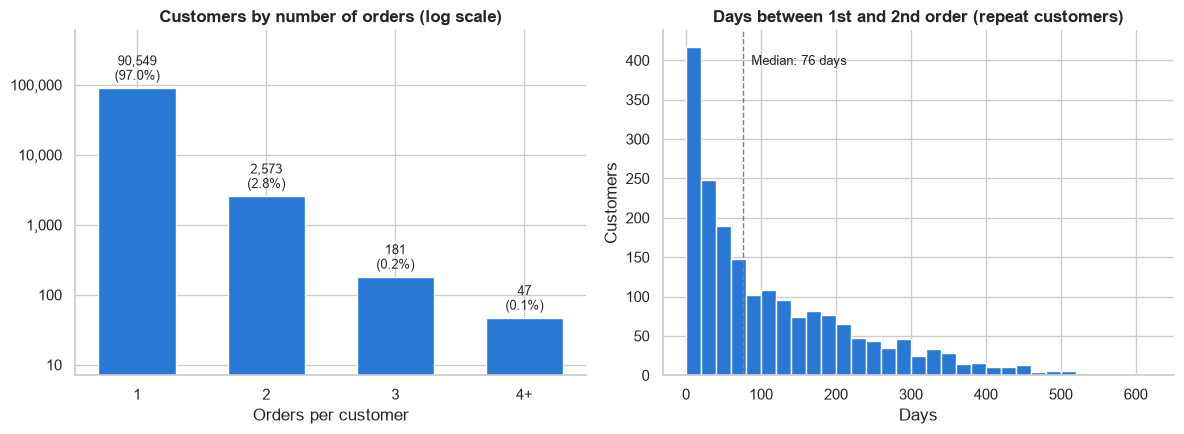

In [118]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: customers by number of orders (log scale: 1-order group is ~30x bigger)
bars = ax1.bar(freq_tbl.index, freq_tbl["customers"], color=BLUE, width=0.6)
ax1.set_yscale("log")
ax1.set_title("Customers by number of orders (log scale)")
ax1.set_xlabel("Orders per customer")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for b, pct in zip(bars, freq_tbl["customers_%"]):
    ax1.annotate(f"{b.get_height():,.0f}\n({pct:.1f}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                 ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax1.margins(y=0.25)

# Right: days from 1st to 2nd order, same-day repeats excluded
ax2.hist(gap_days[gap_days > 0], bins=range(0, 640, 20), color=BLUE, edgecolor="white")
med = gap_days[gap_days > 0].median()
ax2.axvline(med, color="gray", ls="--", lw=1)
ax2.annotate(f"Median: {med:.0f} days", (med, ax2.get_ylim()[1] * 0.9), xytext=(6, 0),
             textcoords="offset points", fontsize=9)
ax2.set_title("Days between 1st and 2nd order (repeat customers)")
ax2.set_xlabel("Days")
ax2.set_ylabel("Customers")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "02_purchase_frequency.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - almost nobody comes back, and many "repeat" orders are not real returns**

- **97.0%** of customers ordered only once. The 2,801 repeat customers (3.0%) bring only **5.5%** of revenue. A repeat customer is worth ~1.9x a one-time customer in total (~260 vs ~138 BRL).
- **30.5%** of second orders were placed on the **same day** as the first one. These look like split baskets, not customers who came back. Real returning customers (second order on a later day) are only about **2.1%**.
- For customers who really came back, the **median gap is 76 days** (about 2.5 months), with a long tail up to ~600 days.
- Caveat: customers who joined in 2018 had little time to return before the data ends, so the true repeat rate is likely a bit higher than measured.

**Implications for the next steps:**
- RFM (2.3): Frequency is 1 for 97% of customers, so it will barely separate customers. Recency and Monetary will do most of the work.
- Churn (2.5): the target must ignore same-day second orders, and the observation window must be long enough (well above 76 days) to give customers a fair chance to return.


## 6. What does a typical order look like?

**Questions:** How is order value distributed? Are there extreme orders? How heavy is freight compared to the products' price?


In [119]:
import numpy as np

rev = orders["revenue"]

# --- 1) Distribution summary ---
print(rev.describe(percentiles=[.25, .5, .75, .9, .99]).round(2).to_string())
print(f"\nSkewness: {rev.skew():.1f}   (0 = symmetric; > 1 = strongly right-skewed)")
print(f"Orders with revenue <= 0: {(rev <= 0).sum()}")

# --- 2) How concentrated is revenue in big orders? ---
rev_sorted = rev.sort_values(ascending=False)
for pct in (0.01, 0.10):
    n = int(len(rev_sorted) * pct)
    print(f"Top {pct:.0%} of orders ({n:,}) = {rev_sorted.head(n).sum() / rev.sum():.1%} of revenue")

# --- 3) Freight as a share of the products' price, by order value band ---
bands = pd.cut(rev, bins=[0, 50, 100, 200, 500, 1000, np.inf],
               labels=["<50", "50-100", "100-200", "200-500", "500-1000", "1000+"])
freight_tbl = (orders.assign(band=bands, freight_ratio=orders["freight_value"] / rev * 100)
               .groupby("band", observed=True)
               .agg(orders=("order_id", "count"),
                    median_order_value=("revenue", "median"),
                    median_freight=("freight_value", "median"),
                    median_freight_pct=("freight_ratio", "median")))
freight_tbl["orders_%"] = freight_tbl["orders"] / freight_tbl["orders"].sum() * 100
print()
print(freight_tbl.round(1).to_string())

count    96470.00
mean       137.04
std        209.05
min          0.85
25%         45.90
50%         86.50
75%        149.90
90%        269.00
99%        990.00
max      13440.00

Skewness: 9.9   (0 = symmetric; > 1 = strongly right-skewed)
Orders with revenue <= 0: 0
Top 1% of orders (964) = 11.5% of revenue
Top 10% of orders (9,647) = 41.0% of revenue

          orders  median_order_value  median_freight  median_freight_pct  orders_%
band                                                                              
<50        29044                30.0            15.1                46.1      30.1
50-100     27606                75.0            16.5                22.8      28.6
100-200    25283               139.9            19.2                14.3      26.2
200-500    11060               280.0            24.6                 8.7      11.5
500-1000    2572               659.0            32.3                 4.8       2.7
1000+        905              1377.5            48.7         

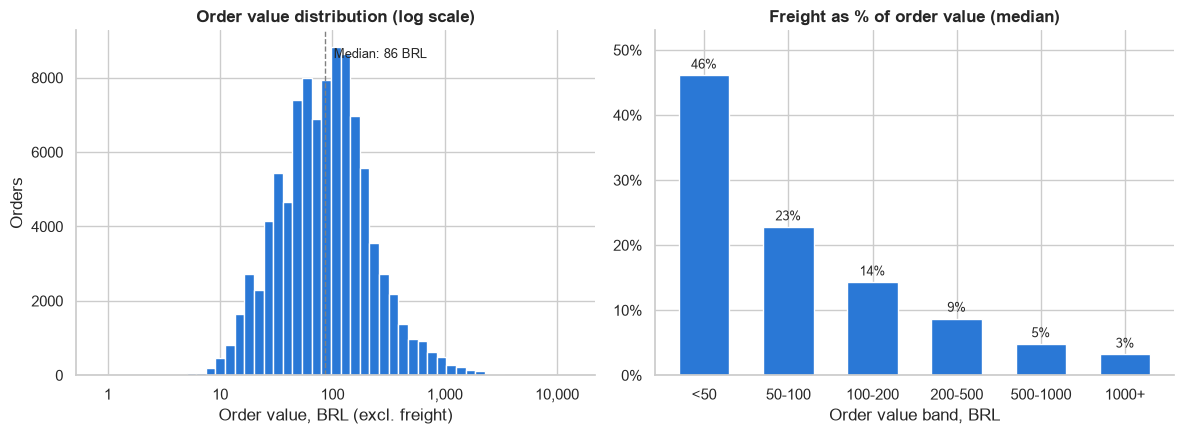

In [120]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: order value on a log x-axis (the distribution is strongly right-skewed)
log_bins = np.logspace(np.log10(rev[rev > 0].min()), np.log10(rev.max()), 50)
ax1.hist(rev[rev > 0], bins=log_bins, color=BLUE, edgecolor="white")
ax1.set_xscale("log")
ax1.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
med = rev.median()
ax1.axvline(med, color="gray", ls="--", lw=1)
ax1.annotate(f"Median: {med:,.0f} BRL", (med, ax1.get_ylim()[1] * 0.92), xytext=(6, 0),
             textcoords="offset points", fontsize=9)
ax1.set_title("Order value distribution (log scale)")
ax1.set_xlabel("Order value, BRL (excl. freight)")
ax1.set_ylabel("Orders")

# Right: median freight as % of products' price, per order value band
bars = ax2.bar(freight_tbl.index.astype(str), freight_tbl["median_freight_pct"], color=BLUE, width=0.6)
for b in bars:
    ax2.annotate(f"{b.get_height():.0f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                 ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax2.set_title("Freight as % of order value (median)")
ax2.set_xlabel("Order value band, BRL")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.margins(y=0.15)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "03_order_value_freight.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - small orders dominate, and freight is a heavy extra cost on them**

- The typical order is small: **median 86.5 BRL**, while the mean is 137 BRL. Skewness is **9.9**, so a few large orders (max 13,440 BRL) pull the mean up. The median is the honest "typical order".
- On a log scale the distribution looks roughly bell-shaped (log-normal). No zero or negative values, and the large orders look like expensive products, not data errors, so we keep them.
- Revenue is concentrated: the **top 10% of orders bring 41% of revenue** (top 1% = 11.5%).
- Freight is a big burden on cheap orders: for orders **under 50 BRL (30% of all orders)** the median freight equals **46%** of the products' price; for 50-100 BRL orders it is 23%. Above 500 BRL it drops below 5%.

**Implications:**
- K-Means (2.4): order and customer value must be **log-transformed** before clustering; otherwise a few big spenders dominate the clusters.
- Churn (2.5-2.6): the freight-to-price ratio is a good candidate feature. Hypothesis to test: customers who paid high freight on a small first order are less likely to come back. (Not proven yet: this is a correlation to check, not a cause.)


## 7. Does late delivery hurt reviews and repeat purchases?

**Questions:** How does the review score change with delivery delay? And does a late **first** order make a customer less likely to come back?


In [121]:
# delay_days = delivered date - estimated date (+ = late). NULL when delivery dates are invalid.
d = orders.dropna(subset=["delay_days", "review_score"]).copy()
print(f"Orders with valid delivery dates and a review: {len(d):,} of {len(orders):,}")

# --- 1) Review score by delay band ---
d["delay_band"] = pd.cut(d["delay_days"], bins=[-np.inf, -15, -1, 0, 3, 7, 14, np.inf],
                         labels=["15+ days early", "1-14 early", "On the day", "1-3 late",
                                 "4-7 late", "8-14 late", "15+ late"])
review_tbl = (d.groupby("delay_band", observed=True)
               .agg(orders=("order_id", "count"),
                    avg_review=("review_score", "mean"),
                    bad_review_pct=("review_score", lambda s: (s <= 2).mean() * 100)))
print()
print(review_tbl.round(2).to_string())

# Cross-check with Phase 1 (late avg 2.27 vs on time 4.29)
print()
print(d.groupby(d["delay_days"] > 0)["review_score"].mean().rename({False: "on time", True: "late"}).round(2).to_string())

# --- 2) Late FIRST order vs coming back (2nd order on a later day) ---
# Only customers whose first order was before 2018-03-01, so everyone had 6+ months to return.
first = orders[orders["order_seq"] == 1][["customer_key", "purchase_date", "is_late", "review_score"]]
second = (orders[orders["order_seq"] == 2][["customer_key", "purchase_date"]]
          .rename(columns={"purchase_date": "second_date"}))
fc = first.merge(second, on="customer_key", how="left")
fc["returned"] = (fc["second_date"] > fc["purchase_date"]).astype(int)   # same-day 2nd order does not count
fc = fc[(fc["purchase_date"] < "2018-03-01") & fc["is_late"].notna()]
fc["first_order"] = np.where(fc["is_late"].astype(int) == 1, "Late", "On time")

return_tbl = fc.groupby("first_order").agg(customers=("customer_key", "count"),
                                           return_rate_pct=("returned", lambda s: s.mean() * 100))
print()
print(return_tbl.round(2).to_string())

Orders with valid delivery dates and a review: 95,637 of 96,470

                orders  avg_review  bad_review_pct
delay_band                                        
15+ days early   34670        4.32            9.02
1-14 early       53309        4.27            9.34
On the day        1279        4.03           12.43
1-3 late          1851        3.29           32.14
4-7 late          1747        2.10           67.66
8-14 late         1446        1.67           80.15
15+ late          1335        1.72           78.35

delay_days
on time    4.29
late       2.27

             customers  return_rate_pct
first_order                            
Late              3674             1.85
On time          51828             2.85


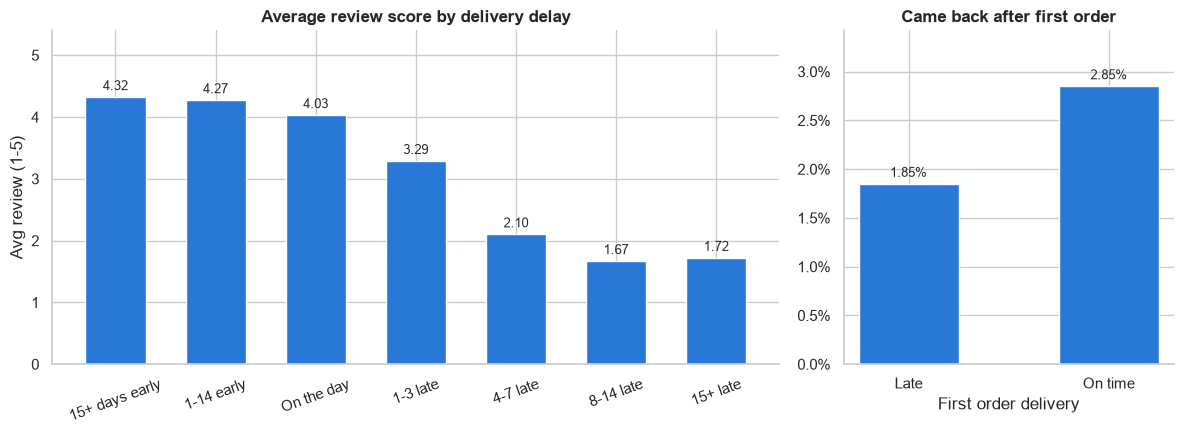

In [122]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

# Left: average review by delay band
bars = ax1.bar(review_tbl.index.astype(str), review_tbl["avg_review"], color=BLUE, width=0.6)
for b in bars:
    ax1.annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                 ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax1.set_ylim(0, 5.4)
ax1.set_title("Average review score by delivery delay")
ax1.set_ylabel("Avg review (1-5)")
ax1.tick_params(axis="x", labelrotation=20)

# Right: return rate after a late vs on-time first order
bars = ax2.bar(return_tbl.index, return_tbl["return_rate_pct"], color=BLUE, width=0.5)
for b in bars:
    ax2.annotate(f"{b.get_height():.2f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                 ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax2.set_title("Came back after first order")
ax2.set_xlabel("First order delivery")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax2.margins(y=0.2)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "04_delay_review_return.png", dpi=150, bbox_inches="tight")
plt.show()

In [123]:
from scipy.stats import norm

# Is the gap in return rate (late vs on-time first order) real, or just noise?
# Two-proportion z-test: H0 = both groups have the same return rate.
g = fc.groupby("first_order")["returned"].agg(["sum", "count"])
x1, n1 = g.loc["Late", "sum"], g.loc["Late", "count"]
x2, n2 = g.loc["On time", "sum"], g.loc["On time", "count"]
p1, p2, p_pool = x1 / n1, x2 / n2, (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z = (p1 - p2) / se
p_value = 2 * norm.sf(abs(z))

print(f"Late:    {x1:,} of {n1:,} returned = {p1:.2%}")
print(f"On time: {x2:,} of {n2:,} returned = {p2:.2%}")
print(f"Relative difference: {(p1 / p2 - 1):.0%}")
print(f"z = {z:.2f}, p-value = {p_value:.4f}  ->  {'significant' if p_value < 0.05 else 'not significant'} at 5%")

Late:    68 of 3,674 returned = 1.85%
On time: 1,478 of 51,828 returned = 2.85%
Relative difference: -35%
z = -3.56, p-value = 0.0004  ->  significant at 5%


**Insight - lateness destroys reviews and is linked to fewer returns**

- Reviews are stable while the order arrives on or before the estimated date (**4.0-4.3**). They drop as soon as the order is late: **3.29** at 1-3 days late, **2.10** at 4-7 days, and **~1.7** beyond a week, where about **80%** of reviews are 1-2 stars.
- Matches Phase 1 exactly: late **2.27** vs on time **4.29**.
- Customers whose **first** order arrived late came back less often: **1.85% vs 2.85%** (**35% lower**). The z-test above confirms the gap is **statistically significant** (z = -3.56, p = 0.0004), so it is very unlikely to be random noise.
- Caveat: this is a correlation. Late orders may also differ in region or product type, so we will check the effect again inside the churn model, together with other features.

**Business meaning:** the first 3 days of delay are where the damage starts, and after 4 days most customers are unhappy. Since Olist already over-estimates delivery time by ~12 days (Phase 1), keeping orders within the promised date is achievable and protects both reviews and repeat purchases.


## 8. Where is the revenue, and where are the delivery problems?

**Questions:** Which states bring the most revenue? Which states suffer most from late deliveries? Are the two the same places?


In [124]:
# Late flag as a number (1 = late, 0 = on time, NaN = invalid delivery dates)
o = orders.assign(late=pd.to_numeric(orders["is_late"], errors="coerce"))

state_tbl = (o.groupby("customer_state")
              .agg(orders=("order_id", "count"),
                   revenue=("revenue", "sum"),
                   aov=("revenue", "mean"),
                   late_rate_pct=("late", lambda s: s.mean() * 100),
                   avg_review=("review_score", "mean"))
              .sort_values("revenue", ascending=False))
state_tbl["revenue_share_pct"] = state_tbl["revenue"] / state_tbl["revenue"].sum() * 100
state_tbl["cum_share_pct"] = state_tbl["revenue_share_pct"].cumsum()

overall_late = o["late"].mean() * 100
print(f"States: {len(state_tbl)} | overall late rate: {overall_late:.1f}%")
print(f"Top 3 states = {state_tbl['revenue_share_pct'].head(3).sum():.1f}% of revenue\n")
print(state_tbl.head(10)[["orders", "revenue_share_pct", "cum_share_pct", "aov",
                          "late_rate_pct", "avg_review"]].round(1).to_string())

# Cross-check with Phase 1: SP 38.3% of revenue; late rate CE 13.8%, BA 12.2%, RJ 12.1%, SP 4.5%
print()
print(state_tbl.loc[["SP", "RJ", "BA", "CE"], ["revenue_share_pct", "late_rate_pct"]].round(1).to_string())

States: 27 | overall late rate: 6.8%
Top 3 states = 63.4% of revenue

                orders  revenue_share_pct  cum_share_pct    aov  late_rate_pct  avg_review
customer_state                                                                            
SP               40499               38.3           38.3  125.2            4.5         4.2
RJ               12351               13.3           51.6  142.5           12.1         4.0
MG               11351               11.7           63.4  136.7            4.6         4.2
RS                5344                5.5           68.9  136.4            6.1         4.2
PR                4921                5.0           73.9  135.2            4.1         4.2
SC                3547                3.8           77.8  142.9            8.2         4.1
BA                3254                3.7           81.5  151.6           12.2         3.9
DF                2077                2.2           83.7  142.4            5.6         4.1
GO                19

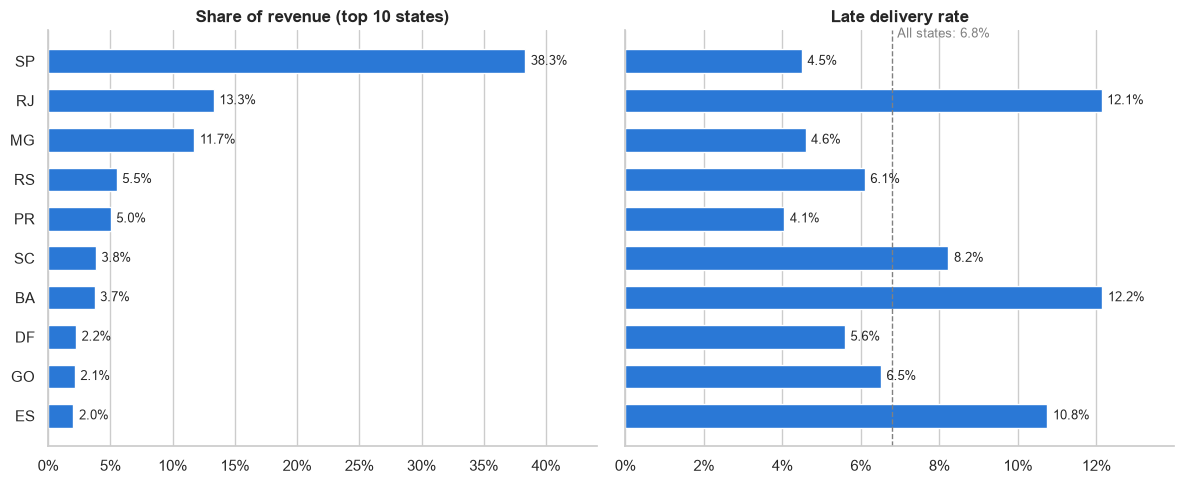

In [125]:
top = state_tbl.head(10).iloc[::-1]   # top 10 by revenue, largest at the top of the chart

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: share of revenue
bars = ax1.barh(top.index, top["revenue_share_pct"], color=BLUE, height=0.6)
for b in bars:
    ax1.annotate(f"{b.get_width():.1f}%", (b.get_width(), b.get_y() + b.get_height() / 2),
                 va="center", fontsize=9, xytext=(4, 0), textcoords="offset points")
ax1.set_title("Share of revenue (top 10 states)")
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.margins(x=0.15)

# Right: late delivery rate for the same states, with the overall average
bars = ax2.barh(top.index, top["late_rate_pct"], color=BLUE, height=0.6)
for b in bars:
    ax2.annotate(f"{b.get_width():.1f}%", (b.get_width(), b.get_y() + b.get_height() / 2),
                 va="center", fontsize=9, xytext=(4, 0), textcoords="offset points")
ax2.axvline(overall_late, color="gray", ls="--", lw=1)
ax2.annotate(f"All states: {overall_late:.1f}%", (overall_late, 9.6), xytext=(4, 0),
             textcoords="offset points", fontsize=9, color="gray")
ax2.set_title("Late delivery rate")
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.margins(x=0.15)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMG_DIR / "05_states_revenue_late.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - revenue is concentrated in the South-East, and Rio de Janeiro is the weak spot**

- 27 states, but the **top 3 (SP, RJ, MG) bring 63.4% of revenue**. SP alone = **38.3%** (matches Phase 1).
- SP has the **lowest average order value** among the top 10 (125 BRL); BA has the highest (152 BRL).
- **RJ is the priority:** it is the 2nd largest market (13.3% of revenue) but has a late rate of **12.1%**, almost 2x the national average (6.8%) and almost 3x SP (4.5%). With about 12,350 orders, that is roughly **1,500 late orders**, close to SP's ~1,800 late orders from 3x more volume. RJ also has the lowest average review of the top 3 (4.0).
- Other states with high late rates are smaller markets: BA 12.2%, ES 10.8%, CE 13.8% (Phase 1).
- Caveat: these are state-level averages; the cause (carrier, distance, seller location) is not in this view and needs a deeper check.

**Business meaning:** fixing delivery in RJ gives the biggest return. It is a large market, lateness there is high, and section 7 showed that a late first order cuts the chance of a repeat purchase by about a third.


## 9. Do new customers come back in the following months? (Cohort retention)

**Question:** For each group of customers who bought for the first time in the same month (a *cohort*), what % were active again 1, 2, 3 ... 12 months later?


In [126]:
# Cohorts that started inside the analysis window
c = cohort[cohort["cohort_month"].between(START, END)]

sizes = c[c["month_number"] == 0].groupby("cohort_month")["customer_key"].nunique()
active = (c.groupby(["cohort_month", "month_number"])["customer_key"].nunique()
           .unstack(fill_value=0)
           .reindex(columns=range(0, 20), fill_value=0))
retention = active.div(sizes, axis=0) * 100

# Months after the end of the data cannot be observed -> NaN (not 0%)
for cm in retention.index:
    months_left = (END.year - cm.year) * 12 + (END.month - cm.month)
    retention.loc[cm, retention.columns > months_left] = np.nan

ret12 = retention.loc[:, 1:12]

# Weighted average across cohorts (bigger cohorts count more), only where observable
observed = ret12.notna()
avg_curve = (active.loc[:, 1:12].where(observed).sum()
             / observed.mul(sizes, axis=0).sum() * 100)
print("Average retention by month (% of cohort active again):")
print(avg_curve.round(2).to_string())

# Cross-check with Phase 1: Nov 2017 cohort = 7,059 customers, 40 active in month 1
nov = pd.Timestamp("2017-11-01")
print(f"\nNov 2017 cohort: {sizes[nov]:,} customers, month 1 active: {active.loc[nov, 1]} "
      f"({retention.loc[nov, 1]:.1f}%)")

Average retention by month (% of cohort active again):
month_number
1     0.48
2     0.34
3     0.26
4     0.26
5     0.23
6     0.23
7     0.21
8     0.20
9     0.16
10    0.25
11    0.22
12    0.17

Nov 2017 cohort: 7,059 customers, month 1 active: 40 (0.6%)


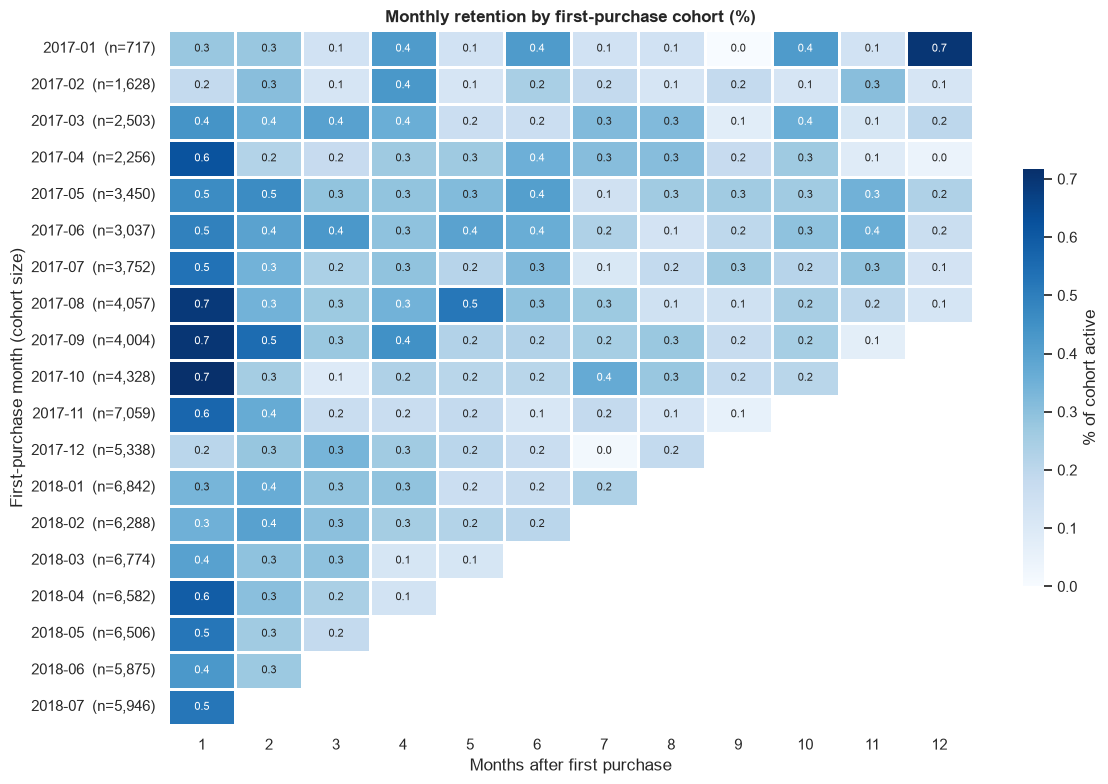

In [127]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_df = ret12.dropna(how="all")   # drop cohorts with no observable month yet (Aug 2018)
labels = [f"{cm:%Y-%m}  (n={sizes[cm]:,})" for cm in plot_df.index]
sns.heatmap(plot_df, ax=ax, cmap="Blues", vmin=0, annot=True, fmt=".1f",
            annot_kws={"fontsize": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "% of cohort active", "shrink": 0.6},
            yticklabels=labels, mask=plot_df.isna())
ax.grid(False)   # no grid lines behind the empty (not yet observable) cells
ax.set_title("Monthly retention by first-purchase cohort (%)")
ax.set_xlabel("Months after first purchase")
ax.set_ylabel("First-purchase month (cohort size)")
ax.tick_params(axis="y", labelrotation=0)

fig.tight_layout()
fig.savefig(IMG_DIR / "06_cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - retention is flat and very low in every cohort**

- On average only **0.48%** of a cohort buys again in the month after the first purchase. After that it settles at **~0.2-0.3% per month**, with no clear decline and no clear peak, up to month 12.
- Adding months 1-12 gives about **3%**, which matches the 3% repeat-customer rate from section 5.
- **No cohort ever goes above 0.7%** in any month, and 2018 cohorts are not better than 2017 ones: retention did **not improve** while the business grew.
- The Nov 2017 (Black Friday) cohort is the largest (7,059 customers) but is not retained better: 0.6% in month 1 (40 customers, matches Phase 1), then 0.1-0.4%.
- Caveat: values are tiny (often a few dozen customers per cell), so single cells move by chance; the overall pattern is what matters.

**Business meaning:** there is no "loyal core" forming over time. Month 1 is the strongest moment to bring a customer back, so a follow-up campaign in the first weeks after delivery is the most natural lever. For churn (2.5), returns are spread over many months, which again supports a long observation window.


## 10. Summary of EDA findings

| # | Finding | Evidence |
|---|---------|----------|
| 1 | Growth came only from **more orders**; it stalled in 2018 | Jan-Aug 2018 vs 2017: revenue +141%, orders +140%, AOV flat (~136 BRL) |
| 2 | Almost nobody comes back | 97% one-time buyers; real returners ~2.1% (30.5% of 2nd orders are same-day split baskets) |
| 3 | Returning customers take a long time | Median 76 days from 1st to 2nd order, tail up to ~600 days |
| 4 | Typical order is small; freight hurts small orders | Median order 86.5 BRL; under 50 BRL, freight = 46% of the price |
| 5 | Late delivery destroys reviews | 4.0-4.3 on time -> 2.10 at 4-7 days late -> ~1.7 beyond a week |
| 6 | Late first order = fewer returns | 1.85% vs 2.85% return rate (-35%), z-test p = 0.0004 |
| 7 | Rio de Janeiro is the logistics weak spot | 2nd largest market (13.3% of revenue), 12.1% late vs 6.8% overall |
| 8 | Retention never improved | ~0.48% back in month 1, ~0.2-0.3%/month after; 2018 cohorts no better than 2017 |

**Overall story:** Olist grew by acquiring new customers, not by keeping them. Retention is the main growth lever, and on-time delivery (especially in RJ) is the clearest operational action linked to it.

**Decisions carried into the next steps:**
- **RFM (2.3):** Frequency is almost constant (1 for 97%), so Recency and Monetary carry most of the signal.
- **K-Means (2.4):** log-transform monetary values before scaling (skewness 9.9).
- **Churn (2.5-2.6):** ignore same-day second orders; use a long observation window (well beyond 76 days); candidate features include first-order lateness, review score and freight-to-price ratio, all measured **before** the cutoff date.
